# Barrier options

Checks on `pricing.barrier`:

1. **Closed form vs. Monte Carlo**, with and without the Brownian-bridge correction: how large the discrete-monitoring bias is as a function of the number of time steps.
2. **Price vs. barrier level**, and in-out parity.
3. **Greeks near the barrier**: why a trader quoted a barrier does not hedge it like a vanilla.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pricing.barrier import barrier_mc_price, barrier_price
from pricing.black_scholes import black_scholes_price
from pricing.greeks import analytical_greeks

In [2]:
# Market parameters (same as previous notebooks, for comparability)
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20
q = 0.02

H = 90.0  # down barrier used in section 1
vanilla = black_scholes_price(S0, K, T, r, sigma, "call", q)
exact = barrier_price(S0, K, H, T, r, sigma, "call", "down-and-out", q)
print(f"Vanilla call:                  {vanilla:.5f}")
print(f"Down-and-out call, H = {H:.0f}:     {exact:.5f}  (continuous monitoring, closed form)")

Vanilla call:                  9.22701
Down-and-out call, H = 90:     7.58695  (continuous monitoring, closed form)


## 1. Discrete monitoring bias and the Brownian bridge

If the simulation only looks at the barrier at the grid dates, a path can cross $H$ and come back between two dates without being noticed. For a knock-out this means too many paths survive and the price is too high. The bridge correction weights each path by the exact probability that a Brownian bridge between the two observed endpoints did not touch $H$.

In [3]:
rows = []
for n_steps in [4, 12, 50, 252, 1000]:
    naive = barrier_mc_price(S0, K, H, T, r, sigma, "call", "down-and-out", q, n_paths=200_000, n_steps=n_steps, brownian_bridge=False, seed=5)
    fixed = barrier_mc_price(S0, K, H, T, r, sigma, "call", "down-and-out", q, n_paths=200_000, n_steps=n_steps, brownian_bridge=True, seed=5)
    rows.append({"n_steps": n_steps,
                 "naive bias": naive.price - exact, "naive SE": naive.std_error,
                 "bridge bias": fixed.price - exact, "bridge SE": fixed.std_error})
df_bias = pd.DataFrame(rows)
df_bias.round(4)

,n_steps,naive bias,naive SE,bridge bias,bridge SE
0,4,1.2086,0.0309,0.0275,0.0293
1,12,0.8370,0.0309,-0.0019,0.0299
2,50,0.4444,0.0308,-0.0218,0.0303
3,252,0.2493,0.0307,0.0276,0.0305
4,1000,0.1425,0.0306,0.0220,0.0305


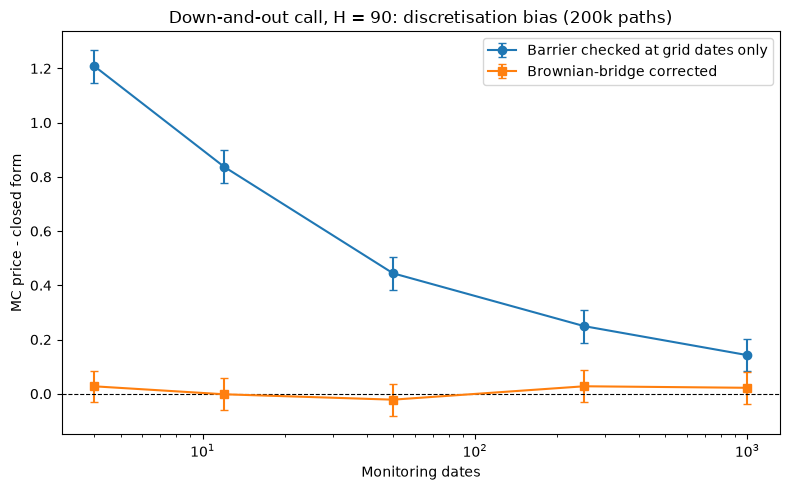

,n_steps,naive bias (MC),predicted by shifting H
0,4,1.2086,1.1848
1,12,0.8370,0.8330
2,50,0.4444,0.4693
3,252,0.2493,0.2252
4,1000,0.1425,0.1165


In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(df_bias["n_steps"], df_bias["naive bias"], yerr=1.96 * df_bias["naive SE"], fmt="o-", capsize=3, label="Barrier checked at grid dates only")
ax.errorbar(df_bias["n_steps"], df_bias["bridge bias"], yerr=1.96 * df_bias["bridge SE"], fmt="s-", capsize=3, label="Brownian-bridge corrected")
# The known leading-order shift: monitoring discretely at spacing dt moves the barrier away by about 0.5826 * sigma * sqrt(dt) * H.
ax.axhline(0, color="k", linestyle="--", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("Monitoring dates")
ax.set_ylabel("MC price - closed form")
ax.set_title("Down-and-out call, H = 90: discretisation bias (200k paths)")
ax.legend()
fig.tight_layout()
plt.show()

# Check the Broadie-Glasserman-Kou continuity correction: discrete monitoring ~ continuous monitoring with barrier shifted by exp(+-0.5826 sigma sqrt(dt)).
shifted = [barrier_price(S0, K, H * np.exp(-0.5826 * sigma * np.sqrt(T / n)), T, r, sigma, "call", "down-and-out", q) - exact for n in df_bias["n_steps"]]
pd.DataFrame({"n_steps": df_bias["n_steps"], "naive bias (MC)": df_bias["naive bias"], "predicted by shifting H": shifted}).round(4)

**Reading the bias table**

- Without the bridge the knock-out is overpriced by 1.21 with 4 dates, 0.84 with 12, 0.44 with 50, 0.25 with 252 and 0.14 with 1000 (the vanilla is 9.23 and the continuous knock-out 7.59, so 4 monitoring dates overprice it by 16%). It decays slowly, roughly by a factor of 1.8 for every 4 times more dates (about $1/\sqrt{n}$): even daily monitoring (252) leaves a bias of 8 standard errors.
- With the bridge the bias is $-0.02$ to $+0.03$ at every $n$ with standard error 0.03, so indistinguishable from zero even with 4 dates. The correction is exact for GBM between dates; it does not need a finer grid.
- The second table checks a classical rule of thumb (Broadie-Glasserman-Kou): discrete monitoring with spacing $\Delta t$ behaves like continuous monitoring with the barrier moved away from the spot by a factor $e^{0.5826\sigma\sqrt{\Delta t}}$. It predicts the naive MC bias to within 0.026 at every $n$ (0.024, 0.004, 0.025, 0.024, 0.026), which is about one MC standard error: the rule is a first-order approximation, and the data cannot say whether the remaining differences are noise.

## 2. Price vs. barrier level, and in-out parity

Knock-in and knock-out prices add up to the vanilla price. In `pricing.barrier` the knock-out is *defined* as vanilla minus knock-in, so the parity check below holds by construction and only guards against bookkeeping mistakes. The independent check is the next cell: the closed-form knock-in (the A to D building blocks) against a Monte Carlo knock-in simulated with the bridge correction.

max |DO + DI - vanilla|: 0.0 (holds by construction)
max |UO + UI - vanilla|: 0.0 (holds by construction)


down-and-in  H=   85: closed form 0.4675  MC 0.4733 (SE 0.0061)  diff/SE = +0.95


down-and-in  H=   95: closed form 4.3435  MC 4.3639 (SE 0.0206)  diff/SE = +0.99


up-and-in    H=  110: closed form 9.1101  MC 9.1189 (SE 0.0310)  diff/SE = +0.29


up-and-in    H=  130: closed form 6.0877  MC 6.0953 (SE 0.0311)  diff/SE = +0.25


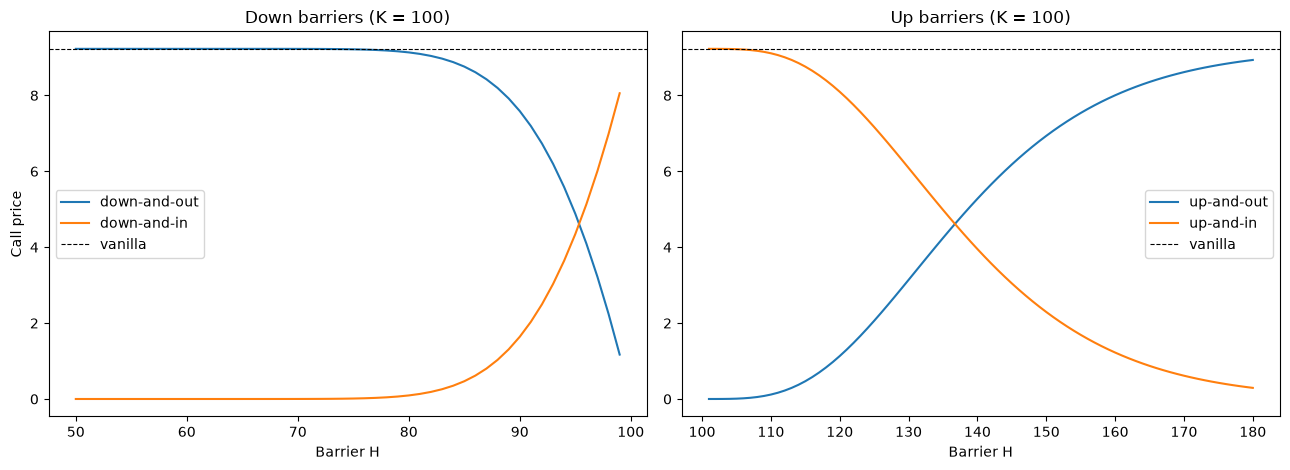

In [5]:
H_dn = np.linspace(50, 99, 50)
H_up = np.linspace(101, 180, 80)
do = np.array([barrier_price(S0, K, h, T, r, sigma, "call", "down-and-out", q) for h in H_dn])
di = np.array([barrier_price(S0, K, h, T, r, sigma, "call", "down-and-in", q) for h in H_dn])
uo = np.array([barrier_price(S0, K, h, T, r, sigma, "call", "up-and-out", q) for h in H_up])
ui = np.array([barrier_price(S0, K, h, T, r, sigma, "call", "up-and-in", q) for h in H_up])

print("max |DO + DI - vanilla|:", np.max(np.abs(do + di - vanilla)), "(holds by construction)")
print("max |UO + UI - vanilla|:", np.max(np.abs(uo + ui - vanilla)), "(holds by construction)")

for btype, h_ in [("down-and-in", 85.0), ("down-and-in", 95.0), ("up-and-in", 110.0), ("up-and-in", 130.0)]:
    cf = barrier_price(S0, K, h_, T, r, sigma, "call", btype, q)
    mc = barrier_mc_price(S0, K, h_, T, r, sigma, "call", btype, q, n_paths=200_000, n_steps=252, seed=9)
    print(f"{btype:12s} H={h_:5.0f}: closed form {cf:.4f}  MC {mc.price:.4f} (SE {mc.std_error:.4f})  diff/SE = {(mc.price - cf) / mc.std_error:+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(H_dn, do, label="down-and-out"); axes[0].plot(H_dn, di, label="down-and-in")
axes[0].axhline(vanilla, color="k", linestyle="--", linewidth=0.8, label="vanilla")
axes[0].set_xlabel("Barrier H"); axes[0].set_ylabel("Call price"); axes[0].set_title("Down barriers (K = 100)"); axes[0].legend()
axes[1].plot(H_up, uo, label="up-and-out"); axes[1].plot(H_up, ui, label="up-and-in")
axes[1].axhline(vanilla, color="k", linestyle="--", linewidth=0.8, label="vanilla")
axes[1].set_xlabel("Barrier H"); axes[1].set_title("Up barriers (K = 100)"); axes[1].legend()
fig.tight_layout()
plt.show()

## 3. Greeks near the barrier

Delta, gamma and vega by central finite differences of the closed-form price (bump 0.01 in spot, 1e-4 in vol), with three months to maturity so that the effects are not washed out. Two cases: a down-and-out call with $H=95$, and an up-and-out call with $H=110$ (strike 100 in both). In an up-and-out the option loses all its value when spot reaches the barrier from below, which is the case that behaves least like a vanilla.

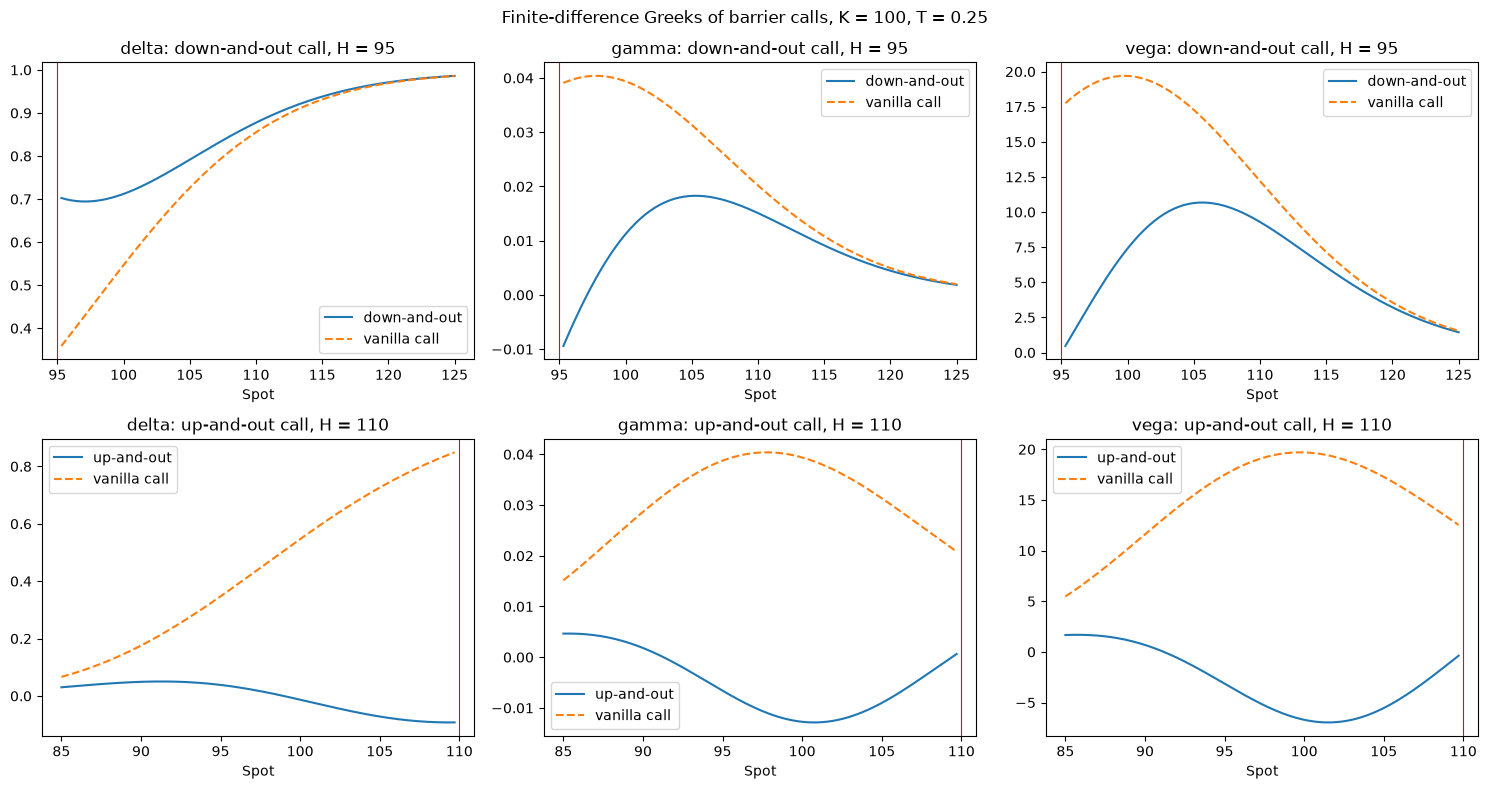

In [6]:
T_g = 0.25

def fd_greeks(S, K_, H_, barrier_type, h=0.01, dv=1e-4):
    f = lambda s, v: barrier_price(s, K_, H_, T_g, r, v, "call", barrier_type, q)
    p, pu, pd_ = f(S, sigma), f(S + h, sigma), f(S - h, sigma)
    return {"price": p, "delta": (pu - pd_) / (2 * h), "gamma": (pu - 2 * p + pd_) / h**2,
            "vega": (f(S, sigma + dv) - f(S, sigma - dv)) / (2 * dv)}

cases = [("down-and-out", 95.0, np.linspace(95.3, 125, 160)), ("up-and-out", 110.0, np.linspace(85, 109.7, 160))]
tables = {}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, (btype, H_, S_) in enumerate(cases):
    g = pd.DataFrame([fd_greeks(s, 100.0, H_, btype) for s in S_], index=S_)
    tables[btype] = g
    van = [analytical_greeks(s, 100.0, T_g, r, sigma, "call", q) for s in S_]
    for col, greek in enumerate(["delta", "gamma", "vega"]):
        ax = axes[row, col]
        ax.plot(S_, g[greek], label=btype)
        ax.plot(S_, [getattr(v, greek) for v in van], "--", label="vanilla call")
        ax.axvline(H_, color="red", linewidth=0.8)
        ax.set_title(f"{greek}: {btype} call, H = {H_:.0f}")
        ax.set_xlabel("Spot")
        ax.legend()
fig.suptitle("Finite-difference Greeks of barrier calls, K = 100, T = 0.25")
fig.tight_layout()
plt.show()

In [7]:
def at(g, spot, col):
    return float(g.loc[g.index[np.argmin(abs(g.index.values - spot))], col])

dn, up = tables["down-and-out"], tables["up-and-out"]
rows = []
for s_ in (96, 100, 110):
    rows.append({"case": "down-and-out H=95", "spot": s_, "price": at(dn, s_, "price"), "delta": at(dn, s_, "delta"), "gamma": at(dn, s_, "gamma"), "vega": at(dn, s_, "vega"),
                 "vanilla delta": analytical_greeks(s_, 100.0, T_g, r, sigma, "call", q).delta,
                 "vanilla gamma": analytical_greeks(s_, 100.0, T_g, r, sigma, "call", q).gamma,
                 "vanilla vega": analytical_greeks(s_, 100.0, T_g, r, sigma, "call", q).vega})
for s_ in (95, 100, 105, 109.5):
    rows.append({"case": "up-and-out H=110", "spot": s_, "price": at(up, s_, "price"), "delta": at(up, s_, "delta"), "gamma": at(up, s_, "gamma"), "vega": at(up, s_, "vega"),
                 "vanilla delta": analytical_greeks(s_, 100.0, T_g, r, sigma, "call", q).delta,
                 "vanilla gamma": analytical_greeks(s_, 100.0, T_g, r, sigma, "call", q).gamma,
                 "vanilla vega": analytical_greeks(s_, 100.0, T_g, r, sigma, "call", q).vega})
pd.DataFrame(rows).round(4)

,case,spot,price,delta,gamma,vega,vanilla delta,vanilla gamma,vanilla vega
0,down-and-out H=95,96.0,0.7339,0.6971,-0.0053,1.6625,0.3866,0.0397,18.3047
1,down-and-out H=95,100.0,3.4760,0.7117,0.0111,7.3770,0.5470,0.0394,19.6932
2,down-and-out H=95,110.0,11.4723,0.8785,0.0150,9.2641,0.8552,0.0202,12.2098
3,up-and-out H=110,95.0,0.5715,0.0389,-0.0065,-3.0758,0.3473,0.0388,17.4885
4,up-and-out H=110,100.0,0.6497,-0.0139,-0.0128,-6.7193,0.5470,0.0394,19.6932
5,up-and-out H=110,105.0,0.4280,-0.0721,-0.0090,-5.5010,0.7264,0.0313,17.2714
6,up-and-out H=110,109.5,0.0419,-0.0923,0.0003,-0.5632,0.8449,0.0213,12.7530


**What the Greeks say**

- **Down-and-out, $H=95$** (spot 96, 1% above the barrier): the knock-out has delta 0.70 against 0.39 for the vanilla, and *negative* gamma ($-0.005$ against $+0.040$). Gamma only turns positive around $S=100$ and is still well below vanilla (0.011 vs 0.039). Vega is 1.7 against 18.3. Near the barrier the value must fall to zero, so the price is steep in spot and concave, and vol is no longer a pure gain.
- **Up-and-out, $H=110$**: the call has *negative* delta from about $S=98$ on ($-0.014$ at 100, $-0.072$ at 105, $-0.092$ at 109.5, against $+0.55$, $+0.73$, $+0.84$ for the vanilla), negative gamma over the whole range ($-0.007$ to $-0.013$) and negative vega ($-6.7$ at the money against $+19.7$). Higher vol makes a knock-out more likely and the option is mainly a bet on *not* touching the barrier.
- Price is continuous at the barrier, but its slope is not: at $S=109.5$ the delta is $-0.09$ and just above the barrier the option does not exist, so the delta jumps from about $-0.09$ to 0. This is the practical headache: a delta hedge that is correct on one side of the barrier is wrong on the other, and gamma and vega change sign as spot moves, so a book of barriers does not hedge like a book of vanillas. In practice desks price this risk with a barrier shift or a hedge with a call spread, which this repository does not implement.